# Predicting Customer Churn for a US Telecom Provider

**An Advanced Analytics practical business case — data preparation,
modeling and evaluation to identify and prioritize at-risk, high-value customers**

## Business context

A telecom company providing mobile plans across the US is losing a
meaningful share of customers to competitors, and wants to act before losing
more high-value customers — but doesn't currently know who to contact first.

This notebook works through four concrete questions:

1. What actually characterizes a customer who is likely to churn?
2. Given a customer's data, what's their probability of churning?
3. Which 500 customers should be contacted first, to maximize retained
   revenue while minimizing churn?
4. How much better is that targeted approach than contacting 500 customers
   at random?

The final answers to all four, written for a non-technical audience, are in
the closing section of this notebook.

## 1. Libraries import

In [562]:
import pandas as pd 
import numpy as np 

import os

import matplotlib.pyplot as plt
import seaborn as sns

import missingno as msno

import functions as fpf

# ML libraries
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, RocCurveDisplay,
    average_precision_score, PrecisionRecallDisplay,
)

## 2. Data load

In [563]:
df = pd.read_csv('./data/churn_all.csv')

## 3. Initial exploration

In [564]:
# basic data exploration
fpf.basic_exploration(df)

What is the shape (dimensions) of the dataframe?


'The dataframe has 5000 rows and 20 columns'

----------------------------------------------------------------------------------------------------
What are the first five rows of the dataframe?


,state,area_code,phone_number,international_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,total_eve_minutes,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls,Churn
0,KS,415,382-4657,no,yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,415,371-7191,no,yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,415,358-1921,no,no,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,408,375-9999,yes,no,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,415,330-6626,yes,no,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


----------------------------------------------------------------------------------------------------
What is a random sample of 5 rows from the dataframe?


...

----------------------------------------------------------------------------------------------------
How many unique values does each column have?


Churn                               2
international_plan                  2
voice_mail_plan                     2
area_code                           3
number_customer_service_calls      10
total_intl_calls                   21
number_vmail_messages              48
state                              51
total_day_calls                   124
total_eve_calls                   126
total_night_calls                 131
total_intl_minutes                170
total_intl_charge                 170
total_night_charge               1028
total_eve_charge                 1659
total_night_minutes              1853
total_eve_minutes                1879
total_day_charge                 1961
total_day_minutes                1961
phone_number                     5000
dtype: int64

----------------------------------------------------------------------------------------------------
What are the unique values of each column?


,0
state,"[KS, OH, NJ, OK, AL, MA, MO, LA, WV, IN, RI, I..."
area_code,"[415, 408, 510]"
phone_number,"[ 382-4657, 371-7191, 358-1921, 375-9999, ..."
international_plan,"[ no, yes]"
voice_mail_plan,"[ yes, no]"
number_vmail_messages,"[25, 26, 0, 24, 37, 27, 33, 39, 30, 41, 28, 34..."
total_day_minutes,"[265.1, 161.6, 243.4, 299.4, 166.7, 223.4, 218..."
total_day_calls,"[110, 123, 114, 71, 113, 98, 88, 79, 97, 84, 1..."
total_day_charge,"[45.07, 27.47, 41.38, 50.9, 28.34, 37.98, 37.0..."
total_eve_minutes,"[197.4, 195.5, 121.2, 61.9, 148.3, 220.6, 348...."


----------------------------------------------------------------------------------------------------


How many null values does each column have?


state                            0
area_code                        0
number_customer_service_calls    0
total_intl_charge                0
total_intl_calls                 0
total_intl_minutes               0
total_night_charge               0
total_night_calls                0
total_night_minutes              0
total_eve_charge                 0
total_eve_calls                  0
total_eve_minutes                0
total_day_charge                 0
total_day_calls                  0
total_day_minutes                0
number_vmail_messages            0
voice_mail_plan                  0
international_plan               0
phone_number                     0
Churn                            0
dtype: int64

----------------------------------------------------------------------------------------------------
What is the percentage of null values per column?


,Column,Percentage
0,state,0.0
1,area_code,0.0
2,number_customer_service_calls,0.0
3,total_intl_charge,0.0
4,total_intl_calls,0.0
5,total_intl_minutes,0.0
6,total_night_charge,0.0
7,total_night_calls,0.0
8,total_night_minutes,0.0
9,total_eve_charge,0.0


----------------------------------------------------------------------------------------------------
Visualization of null values:


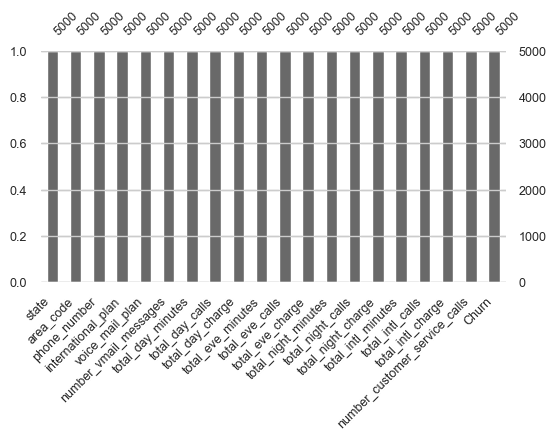

----------------------------------------------------------------------------------------------------
Visualization of the null values pattern:


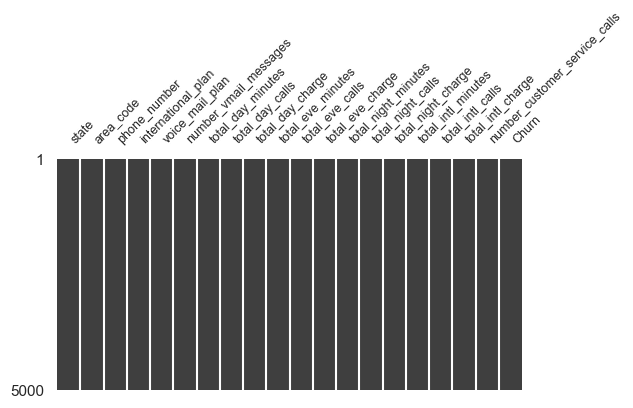

----------------------------------------------------------------------------------------------------


In [565]:
# null exploration
fpf.null_exploration(df)

In [566]:
# duplicate exploration
# each row corresponds to a single customer, therefore, phone numbers should be unique
df['phone_number'].duplicated().sum()

np.int64(0)

## 4. EDA 

### Checking class balance

In [567]:
df['Churn'].value_counts(normalize=True)

Churn
False    0.8586
True     0.1414
Name: proportion, dtype: float64

There is a clear class imbalance in the churn category that should be address when building the predictive model

### Churn rate by state

In [568]:
# do some states have significantly higher churn rates than others?
churn_rate_by_state = df.groupby('state').Churn.agg(['count','sum'])

In [569]:
churn_rate_by_state['churn rate'] = churn_rate_by_state['sum'] / churn_rate_by_state['count']
churn_rate_by_state = churn_rate_by_state.drop(['count', 'sum'], axis=1)
churn_rate_by_state = churn_rate_by_state.sort_values(by='churn rate', ascending=False)

Text(0, 0.05084745762711865, ' Min: 0.051')

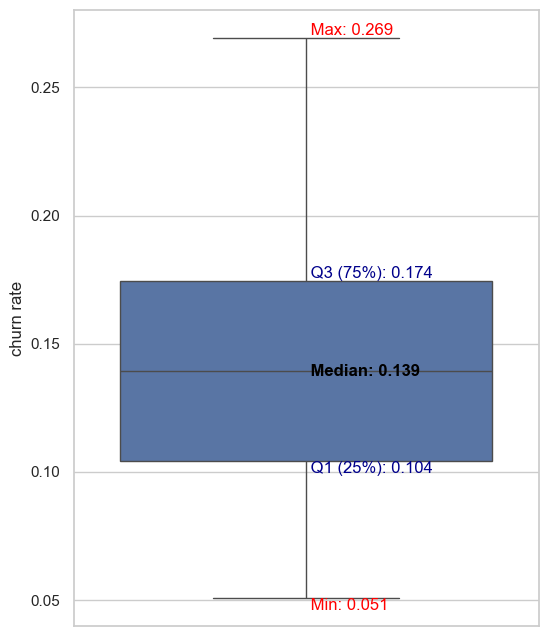

In [570]:
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(6, 8))
sns.boxplot(data=churn_rate_by_state, y='churn rate')

stats = churn_rate_by_state['churn rate'].describe()
min_val = stats['min']
q1 = stats['25%']
median = stats['50%']
q3 = stats['75%']
max_val = stats['max']

x_pos = 0

ax.text(x_pos, median, f' Median: {median:.3f}', va='center', fontweight='bold', color='black')
ax.text(x_pos, q3, f' Q3 (75%): {q3:.3f}', va='bottom', color='darkblue')
ax.text(x_pos, q1, f' Q1 (25%): {q1:.3f}', va='top', color='darkblue')
ax.text(x_pos, max_val, f' Max: {max_val:.3f}', va='bottom', color='red')
ax.text(x_pos, min_val, f' Min: {min_val:.3f}', va='top', color='red')

In [571]:
df['state'].value_counts().describe()

count     51.000000
mean      98.039216
std       16.562561
min       52.000000
25%       89.000000
50%       98.000000
75%      104.500000
max      158.000000
Name: count, dtype: float64

The churn rate by state varies significantly between 0.05 and 0.27, with the highest-churn state experiencing over 5 times the churn rate of the lowest.\
However, there is an average number of 98 customers per state, which migh not be a sufficiently large sample to affirm that differences between states are significant.

### Churn rate by international plan

In [572]:
df_international_churn = df.groupby('international_plan').Churn.agg(['count','sum'])
df_international_churn['churn rate'] = df_international_churn['sum']/df_international_churn['count']

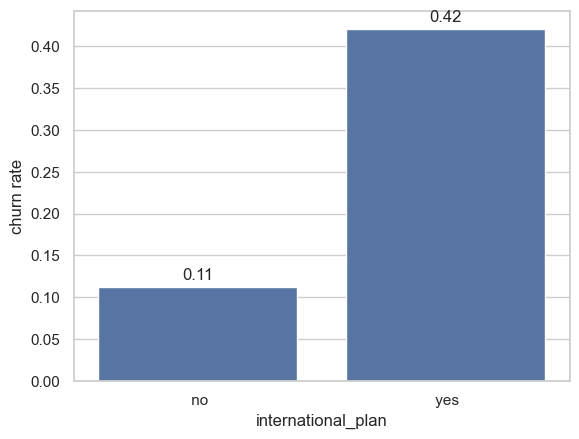

In [573]:
ax = sns.barplot(data=df_international_churn, x='international_plan', y='churn rate')
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
plt.show()

The graph shows a significant difference of approximately 31% in churn rate between customers with international plan (~42% churn rate) and those without(~11% churn rate)

### Churn rate by voice mail plan

In [574]:
df_voicemail_churn = df.groupby('voice_mail_plan').Churn.agg(['count','sum'])
df_voicemail_churn['churn rate'] = df_voicemail_churn['sum']/df_voicemail_churn['count']

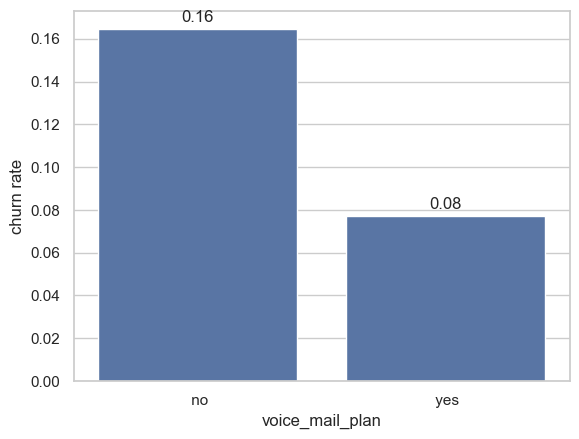

In [575]:
ax = sns.barplot(data=df_voicemail_churn, x='voice_mail_plan', y='churn rate')
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
plt.show()

The graph shows that the churn rate of customers without a voice mail plan (~8% churn rate) approximately doubles that of customers that do have it (~16% churn rate).\
Even though this difference is not as big as that of `international_plan`, it is still very significant for the analysis.

### Churn rate by number of customer service calls

In [576]:
df_cscalls_churn = df.groupby('number_customer_service_calls').Churn.agg(['count','sum'])
df_cscalls_churn['churn rate'] = df_cscalls_churn['sum']/df_cscalls_churn['count']

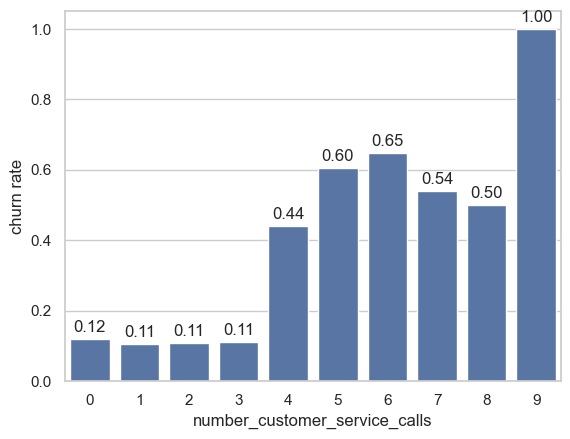

In [577]:
ax =sns.barplot(data=df_cscalls_churn, x='number_customer_service_calls', y='churn rate')
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
plt.show()

The graph shows a noticable increase in churn rate of around 33% after the fourth call, having a maximum churn rate of 100% after the 9th call.

## 5. ML Model

### Model choice

I'm using **Logistic Regression** rather than testing multiple model types:
it outputs calibrated probabilities (which the ranking questions below
require directly, unlike a plain decision boundary), and its coefficients
are directly interpretable.

This requires three decisions:
- **Which columns to use** — resolved in Feature Selection: drop
  `phone_number` and `area_code` as non-predictive identifiers, and the
  `minutes` columns (redundant with `charge`, see the correlation check
  below). `state` was also dropped since we found each state to not have a sufficiently large sample to affirm that differences between states are significant
- **Which hyperparameter to tune** — the regularization strength `C`, tuned
  automatically via `LogisticRegressionCV`'s built-in cross-validation.
- **Which metric to optimize and evaluate on** — `average_precision`
  (PR-AUC), not accuracy or plain ROC-AUC. With only ~14% of customers
  churning, a model can score 86% accuracy by never predicting churn at
  all — Average Precision specifically measures how well the model ranks
  the minority (churn) class, which is exactly what questions 2 and 3
  below need.

### Feature selection

In [578]:
# we don't need these columns
drop_columns = ['state', 'area_code', 'phone_number']
df = df.drop(columns=drop_columns)

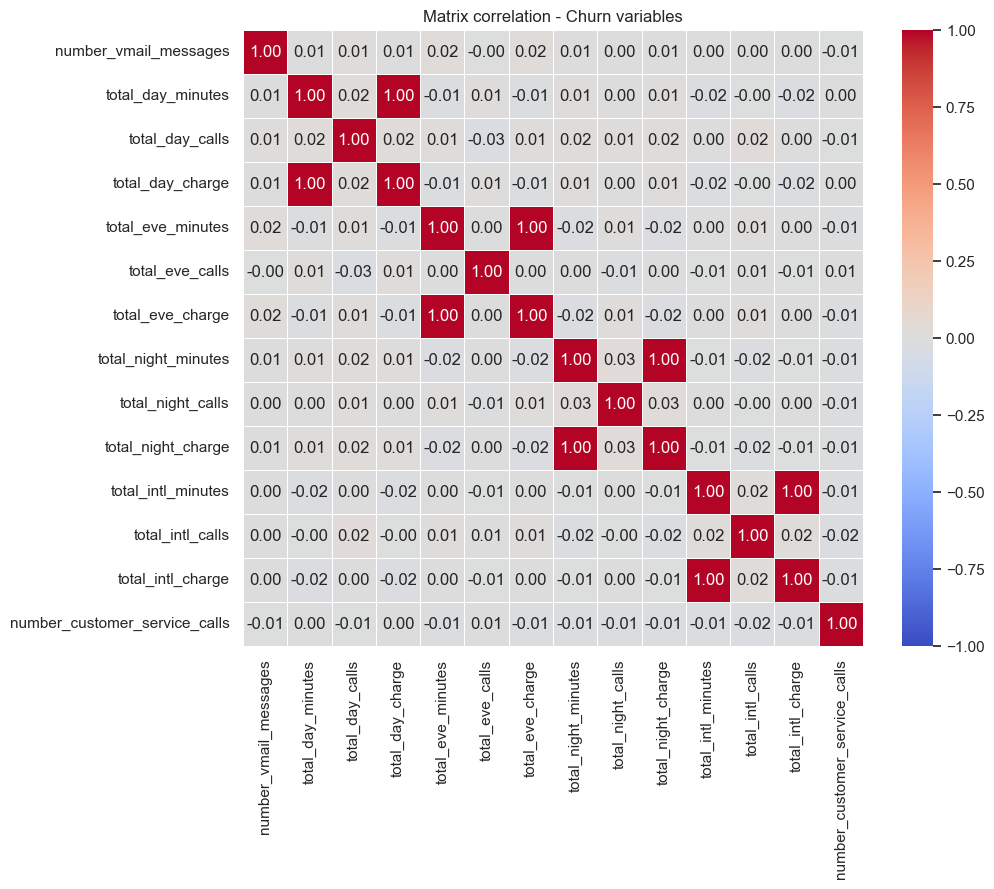

In [579]:
df_numeric = df.select_dtypes('number').copy()
corr_matrix = df_numeric.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True, 
    cmap="coolwarm",
    fmt=".2f", 
    linewidths=0.5,
    vmin=-1,
    vmax=1,
)

plt.title("Matrix correlation - Churn variables")

plt.show()

In [580]:
# to avoid multicolinearity we drop the following columns:
columns_to_drop = ['total_day_minutes', 'total_eve_minutes', 'total_night_minutes', 'total_intl_minutes']
df = df.drop(columns=columns_to_drop)

The correlation heatmap above shows `total_X_minutes` and `total_X_charge`
pairs correlated at ~1.0 for every time-of-day segment — expected, since
charge is simply minutes billed at a fixed rate. Keeping both would add
unstable, redundant coefficients to a linear model without any new
information, so I keep `charge` (closer to the business-relevant unit,
revenue) and drop the corresponding `minutes` columns

### Preprocessing

In [581]:
categorical_cols = ['international_plan', 'voice_mail_plan']
numeric_cols = df.select_dtypes('number').columns.tolist()
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'),categorical_cols),
        ('num', StandardScaler(with_mean=False), numeric_cols)
    ]
)

### Train-test split

In [582]:
x = df[df.columns.drop('Churn')]
y = df['Churn']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

### Model and hyperparameter tunning

In [583]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

logreg = LogisticRegressionCV(
    class_weight='balanced',
    scoring='average_precision',
    cv=cv_strategy,
    max_iter=2000,   
    random_state=42
)

pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('logreg', logreg),
])

### Fit and get probabilities

In [584]:
pipeline.fit(x_train, y_train)

# .predict_proba returns two columns: P(class=False), P(class=True)
# We want the second one, which is the probability of churning for both ranking customers

y_proba = pipeline.predict_proba(x_test)[:, 1]
y_pred = pipeline.predict(x_test)  # hard 0/1 label at the default 0.5 threshold

/opt/anaconda3/envs/science_env/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1780: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/opt/anaconda3/envs/science_env/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1823: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(


### Evaluation

With `predict_proba` computed, evaluation checks two things: how well the
model performs at a fixed 50% cutoff (`classification_report`, `confusion matrix`), 
and how well it ranks customers regardless of any cutoff
(`ROC-AUC`,`PR-AUC`). The second matters more here, since the business
question is about a ranked list, not a fixed threshold.

              precision    recall  f1-score   support

    No churn       0.94      0.78      0.85       859
       Churn       0.34      0.70      0.46       141

    accuracy                           0.77      1000
   macro avg       0.64      0.74      0.66      1000
weighted avg       0.86      0.77      0.80      1000



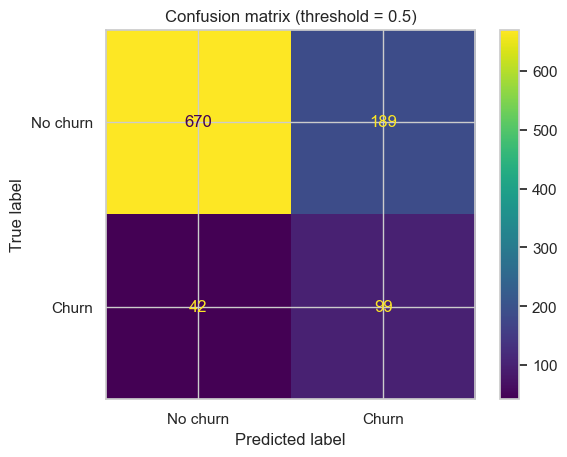

ROC-AUC: 0.829
Average Precision (PR-AUC): 0.469


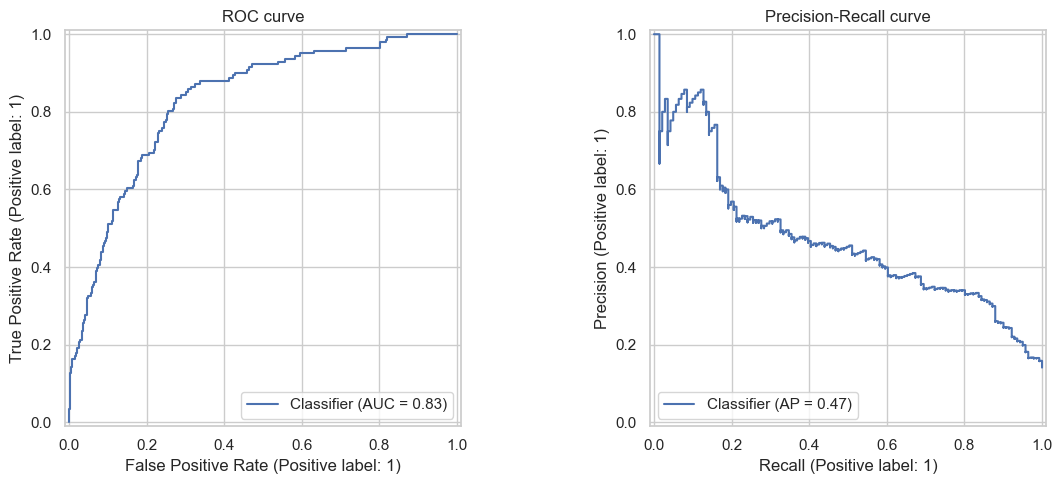

Naive baseline PR-AUC (~= churn rate): 0.141


In [585]:
print(classification_report(y_test, y_pred, target_names=['No churn', 'Churn']))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['No churn','Churn'])
plt.title('Confusion matrix (threshold = 0.5)')
plt.show()

roc_auc = roc_auc_score(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)
print(f"ROC-AUC: {roc_auc:.3f}")
print(f"Average Precision (PR-AUC): {pr_auc:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[0])
axes[0].set_title('ROC curve')
PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=axes[1])
axes[1].set_title('Precision-Recall curve')
plt.tight_layout()
plt.show()

# Naive baseline for context — this is your "vs. random" business question,
# computed here as a sanity check: a model with no skill has PR-AUC roughly
# equal to the churn rate itself (~0.14). Compare pr_auc above to that.
print(f"Naive baseline PR-AUC (~= churn rate): {y_test.mean():.3f}")

#### Reading the evaluation results

Recall for `Churn` (0.70) matters more than precision (0.34) here:
`class_weight='balanced'` trades false alarms for catching more real
churners, since missing a churner costs far more than an unnecessary
contact. `ROC-AUC` (0.829) shows the model correctly ranks a churner above
a non-churner ~83% of the time. `PR-AUC` (0.469) is the more relevant
metric under this imbalance — over 3x the naive baseline (0.141, the
churn rate itself), confirming the model adds real signal beyond just
exploiting the class imbalance

### Cross-validated validation

A single train/test split can be noisy with this few churn cases, so I
validate with 5-fold stratified cross-validation (stratified to keep the
~14% churn ratio in every fold) around the full pipeline

In [586]:
cv_results = cross_validate(
    pipeline, x_train, y_train,
    cv=cv_strategy,
    scoring=['roc_auc', 'average_precision', 'recall', 'precision'],
)

for metric in ['test_roc_auc', 'test_average_precision', 'test_recall', 'test_precision']:
    print(f"{metric}: {cv_results[metric].mean():.3f}  (+/- {cv_results[metric].std():.3f})")

/opt/anaconda3/envs/science_env/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1780: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/opt/anaconda3/envs/science_env/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1823: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(
/opt/anaconda3/envs

test_roc_auc: 0.829  (+/- 0.022)
test_average_precision: 0.454  (+/- 0.040)
test_recall: 0.783  (+/- 0.048)
test_precision: 0.360  (+/- 0.021)


#### Reading the cross-validation results

CV means closely match the single test-set results (ROC-AUC 0.829 both
ways), and the small standard deviations (±0.02–0.05) show performance
is stable across folds rather than split-dependent — this is the basis
for treating the earlier state-vs-no-state difference (0.826 vs. 0.829
ROC-AUC) as noise, since it's smaller than this CV spread.

### Feature importance

/var/folders/6h/76s5lftj1d10282hykft0lm80000gn/T/ipykernel_99799/3385733045.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


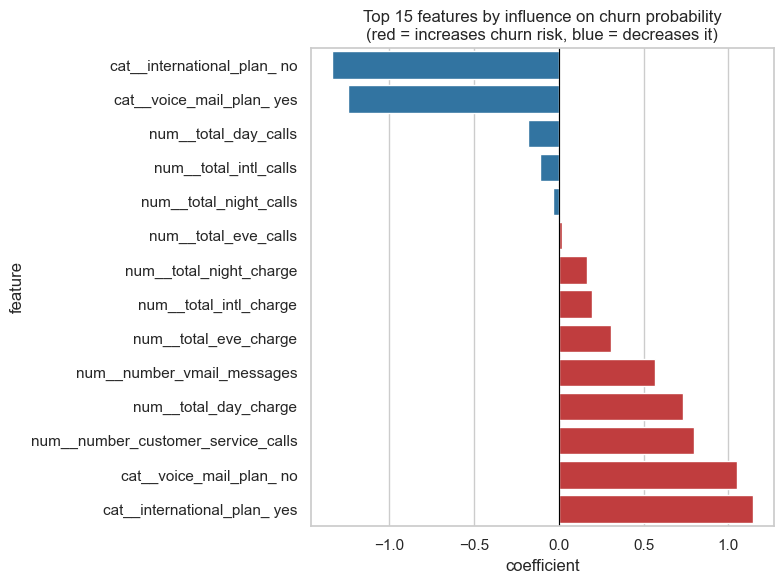

In [587]:
feature_names = pipeline.named_steps['preprocessor'].get_feature_names_out()
coefs = pipeline.named_steps['logreg'].coef_[0]

coef_df = pd.DataFrame({'feature': feature_names, 'coefficient': coefs})
coef_df['abs_coefficient'] = coef_df['coefficient'].abs()
top_features = coef_df.sort_values('abs_coefficient', ascending=False).head(15)

plt.figure(figsize=(8, 6))
sns.barplot(
    data=top_features.sort_values('coefficient'),
    x='coefficient', y='feature',
    palette=['#d62728' if c > 0 else '#1f77b4' for c in top_features.sort_values('coefficient')['coefficient']]
)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Top 15 features by influence on churn probability\n(red = increases churn risk, blue = decreases it)')
plt.tight_layout()
plt.show()

### Key characteristics of customers who churn

Two tiers of signal here, worth treating differently:

**High-confidence signals** (backed by thousands of customers each, and
consistent with the EDA earlier in this notebook):
- Having an **international plan** is the single strongest predictor of
  churn — customers with one churn noticeably more often than those without.
- **Not** having a **voice mail plan** is associated with higher churn.
- More **customer service calls** is associated with higher churn — likely
  a proxy for unresolved problems or dissatisfaction.
- Higher **total day charge** (heavier daytime usage) is associated with
  somewhat higher churn — possibly price sensitivity among heavy users.

### Ranking customers & comparison vs. random

Ranking purely by churn probability, as a first pass, misses half of the
brief's own framing: *"retain their **high-value** customers... maximizing
**profitability**"*. A customer who's 90% likely to churn but generates
little monthly revenue matters less to the business than one who's 60%
likely to churn and pays considerably more — if we can only contact 500
customers, we should prioritize by **expected revenue at risk**, not churn
probability alone.

I don't have an explicit profit or contact-cost figure in the data, so I
use each customer's total monthly charge (day + evening + night +
international) as a revenue proxy, and rank by
`churn_probability × customer_value`. This is a simplification — a real
engagement would refine `customer_value` with actual margin data, and
`churn_probability` with a calibration check — but it's a defensible,
clearly-stated stand-in given what's available.

In [588]:
# Value-weighted prioritization: combine likelihood of churning with
# how much revenue that customer represents, rather than probability alone.
customer_value = (x_test['total_day_charge'] + x_test['total_eve_charge']
                   + x_test['total_night_charge'] + x_test['total_intl_charge'])

ranked = x_test.copy()
ranked['churn_probability'] = y_proba
ranked['actual_churn'] = y_test.values
ranked['customer_value'] = customer_value
ranked['expected_value_at_risk'] = ranked['churn_probability'] * ranked['customer_value']

ranked_by_value = ranked.sort_values('expected_value_at_risk', ascending=False)
top_500_value = ranked_by_value.head(500)

# How many actual churners are in this value-weighted top 500?
churners_captured_value = top_500_value['actual_churn'].sum()

# How much of the total revenue that's actually "at risk" (i.e. belongs to
# real churners) does this top 500 capture?
total_at_risk_value = ranked.loc[ranked['actual_churn'], 'customer_value'].sum()
captured_value = top_500_value.loc[top_500_value['actual_churn'], 'customer_value'].sum()

# Expected capture if instead we just picked 500 customers at random
random_expected_churners = 500 * ranked['actual_churn'].mean()
random_expected_value = 500 * ranked['customer_value'].mean() * ranked['actual_churn'].mean()

print(f"Churners captured (value-weighted top 500): {churners_captured_value}")
print(f"  vs. expected at random: {random_expected_churners:.1f}")
print()
print(f"At-risk revenue captured: ${captured_value:,.0f} of ${total_at_risk_value:,.0f} total")
print(f"  vs. expected at random: ${random_expected_value:,.0f}")
print(f"Revenue-based lift over random: {captured_value / random_expected_value:.2f}x")

Churners captured (value-weighted top 500): 124
  vs. expected at random: 70.5

At-risk revenue captured: $8,392 of $9,207 total
  vs. expected at random: $4,169
Revenue-based lift over random: 2.01x


## Answers for stakeholders

**1. What characterizes a customer who's likely to churn?**
The clearest signals are having an international plan, *not* having a
voice-mail plan, a high number of customer service calls, and heavier
daytime usage

**2. What's a given customer's likelihood of churning?**
The model outputs a probability of churn for any customer, using their
plan type, usage patterns and service-call history. On held-out data it
correctly ranks a customer who churns above one who doesn't about 83% of
the time (ROC-AUC 0.83), confirmed by cross-validation rather than a
single lucky test split.

**3. Which 500 customers should be contacted first?**
Not simply the 500 most likely to churn, the 500 that combine churn risk
with revenue at stake, so retention effort is spent where it protects the
most revenue. This captures $8,392 of the $9,207 in revenue
that's actually at risk in our test sample

**4. How does this compare to contacting customers at random?**
Targeting by the model captures roughly 2 times more
at-risk revenue than picking 500 customers at random, meaning the same
outreach budget protects 2 times more revenue by being targeted correctly

### Caveats
- `customer_value` is approximated from monthly usage charges; a
  refinement with actual customer lifetime value or contact cost would
  sharpen the "profitability" side of the recommendation further.
- Results above are computed on a held-out test sample (1,000 customers)
  for an honest, unbiased read of performance; applying the model to
  the company's full active customer base would follow the same logic
  at scale.